In [6]:
import pymrio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
exio3 = pymrio.parse_exiobase3('IOT_2019_pxp')

### Modue3-Task2

In [8]:
# Define the A matrix:技术/投入系数矩阵，各部门生产 1 单位产出所需的直接投入，描述经济中直接的供应商关系
A = exio3.A

# identify matrix of same size as A
I = np.identity(len(A))

# Lentif inverse: L = (I-A)^-1，满足 1 单位最终需求所需的直接+所有间接投入，可展开为幂级数，对应直接影响、1st/2nd/3rd 供应商及更高层级的影响
L = pd.DataFrame(np.linalg.inv(I-A)) # 求逆：np.linalg.inv()

# Add the right column and index names
L.columns = A.columns
L.index = A.index

In [9]:
Y = exio3.Y                                     # Final demand matrix
A = exio3.A                                     # Inter-industry coefficients
I = np.identity(len(A))                         # Identity matrix
L = np.linalg.inv(I - A)                        # Leontief inverse (as numpy)
L = pd.DataFrame(L, index=A.index, columns=A.columns) # Keep labels

### Module3-Task3

In [10]:
# Task3: 用 Input-output modeling 计算 environmental impacts；评估 production和 consumption 的影响有何不同
# sum(1): F矩阵的原始数据是涉及到每个国家、每个行业一行；在 task3 中，我们只关心全球总排放；sum（1）是横向求和

# F and F_y:to calculate production based impacts
F = exio3.impacts.F
F_Y = exio3.impacts.F_Y
# calculate the production based impacts
D_prod = F.sum(1) + F_Y.sum(1) # note: we need to sum, since F and F_Y do not have the same column names

# S,L,Y,F_Y: to calculate consumption based impacts
S = exio3.impacts.S
Y = exio3.Y
# since we only need the global sum, we can aggregate across all countries in the demand matrix(Y) and final demand impacts(F_Y)
Y_agg = Y.sum(1)
F_Y_agg = F_Y.sum(1)
# calculate the consumptions based impacts
D_cons = S.dot(L).dot(Y_agg) + F_Y_agg

# define the specific indicator that we are interested in
CF = 'GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)'
print(f"Production based: {D_prod[CF]/10**12:.2f} Gt CO2e")
print(f"Consumption based: {D_cons[CF]/10**12:.2f} Gt CO2e")
# 计算结果分析：从全球尺度来看，两个数字非常接近，意味着生产出来的东西都被消费了；但从单个国家尺度来看，如果D_cons 远远大于 D_drop，说明该国家是碳排放出口国


Production based: 49.75 Gt CO2e
Consumption based: 49.74 Gt CO2e


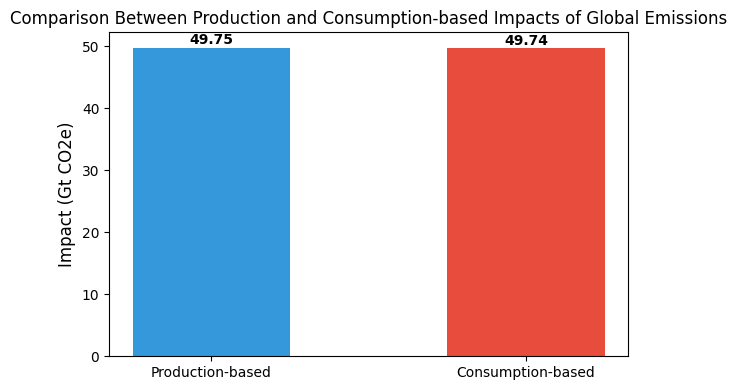

In [11]:
# create a bar graph 
labels = ['Production-based', 'Consumption-based']
values = [D_prod[CF]/10**12, D_cons[CF]/10**12]
plt.subplots(figsize=(6,4))
bars = plt.bar(labels, values, color=['#3498db','#e74c3c'], width=0.5)
plt.ylabel('Impact (Gt CO2e)', fontsize=12)
plt.title("Comparison Between Production and Consumption-based Impacts of Global Emissions")
# 在柱子上方标注具体数值
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.2f}',
             ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()



### Module3-Task4
##### Defintion Macro-sector: 
##### (1)aggregation of EXIOBASE sectors to macro-sectors; (2)Data handling and evaluation

In [12]:
# 这一部分进入对 EXIOBASE 处理：在 MRIO（多区域投入产出）模型中，EXIOBASE 包含数百个行业 sectors
# 定义macro-sector的本质是：从海量的行业中，提取出特定的领域

In [13]:
# settings
extension = 'GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)'
region = 'DK' # Denmark

# 如何实现 macro-sector 定义：核心函数
# not any(ex in s for ex in ["exception"]): 如果名称中包含“例外词”，则剔除；
# any(k in s for k in ['Keyword 1', 'Keyword 2']): 只要行业名称中包含“关键字1”或“关键字2”，就初步选中
def macro_sector(sector):
    s = sector.lower() # 标准化：将行业名称全部转化为小写，防止因为大小写不匹配而漏掉数据
    keywords = ['plastic']
    
    return any(k in s for k in keywords)

# 聚合过程：遍历所有sectors，如果符合函数要求，则存入 my_macro_sector这个 list
my_macro_sector = [
    s for s in exio3.get_sectors() if macro_sector(s)
]

print(f"List of sectors in my macro-sector, {my_macro_sector}")

List of sectors in my macro-sector, ['Plastics, basic', 'Secondary plastic for treatment, Re-processing of secondary plastic into new plastic', 'Rubber and plastic products (25)', 'Plastic waste for treatment: incineration', 'Plastic waste for treatment: landfill']


In [14]:
# settings
extension = 'GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)'
region = 'DK' # Denmark

# 如何实现 macro-sector 定义：核心函数
# not any(ex in s for ex in ["exception"]): 如果名称中包含“例外词”，则剔除；
# any(k in s for k in ['Keyword 1', 'Keyword 2']): 只要行业名称中包含“关键字1”或“关键字2”，就初步选中
def macro_sector(sector):
    s = sector.lower() # 标准化：将行业名称全部转化为小写，防止因为大小写不匹配而漏掉数据
    keywords = ['plastic','polymer','primary forms']
    
    return any(k in s for k in keywords)

# 聚合过程：遍历所有sectors，如果符合函数要求，则存入 my_macro_sector这个 list
my_macro_sector = [
    s for s in exio3.get_sectors() if macro_sector(s)
]

print(f"List of sectors in my macro-sector, {my_macro_sector}")

List of sectors in my macro-sector, ['Plastics, basic', 'Secondary plastic for treatment, Re-processing of secondary plastic into new plastic', 'Rubber and plastic products (25)', 'Plastic waste for treatment: incineration', 'Plastic waste for treatment: landfill']


In [15]:
# settings
extension = 'GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)'
region = 'DK' # Denmark

# 如何实现 macro-sector 定义：核心函数
# not any(ex in s for ex in ["exception"]): 如果名称中包含“例外词”，则剔除；
# any(k in s for k in ['Keyword 1', 'Keyword 2']): 只要行业名称中包含“关键字1”或“关键字2”，就初步选中
def macro_sector(sector):
    s = sector.lower() # 标准化：将行业名称全部转化为小写，防止因为大小写不匹配而漏掉数据
    keywords = ['plastics, basic']
    exceptions = ['secondary', 'treatment', 'waste', 'incineration', 'landfill']
    return not any(ex in s for ex in exceptions) and any(k in s for k in keywords)

# 聚合过程：遍历所有sectors，如果符合函数要求，则存入 my_macro_sector这个 list
my_macro_sector = [
    s for s in exio3.get_sectors() if macro_sector(s)
]

print(f"List of sectors in my macro-sector, {my_macro_sector}")


List of sectors in my macro-sector, ['Plastics, basic']


### Module3-Task5: calculation of macro-sector's impacts
##### (1)manipulation of IOTs; (2) estimation of production and consumption-based impacts using EXIOBASE

In [16]:
# combine the results with the global impacts

# loc[extension]: 筛选，只留下“全球温室气体排放“这一行数据
F = exio3.impacts.F.loc[extension]
F_Y = exio3.impacts.F_Y.loc[extension]
Y=exio3.Y
A =exio3.A
Con = exio3.impacts.D_cba.loc[extension]

# total production-based impact by (region, sector)
D_prod = F + F_Y
# total consumption-based impact by (region, sector)
D_con = Con + F_Y
# 得到一个很大的list，包含全球所有地区和所有行业

# Filter umbrella sectors（这是一个比喻，伞状部门，表示定义的一个大类）
D_prod_umbrella = D_prod.loc[
    D_prod.index.get_level_values('sector').isin(my_macro_sector)
]

D_con_umbrella = D_con.loc[
    D_con.index.get_level_values('sector').isin(my_macro_sector)
    ]

# Denmark only
prod_DK_plastics_total = D_prod_umbrella.loc[region].sum()

con_DK_plastics_total = D_con_umbrella.loc[region].sum()

print("Production-based:", prod_DK_plastics_total, "kg CO2-eq")

print("Consumption-based:", con_DK_plastics_total, "kg CO2-eq")

Production-based: 10833379521.117264 kg CO2-eq
Consumption-based: 17732835104.78826 kg CO2-eq


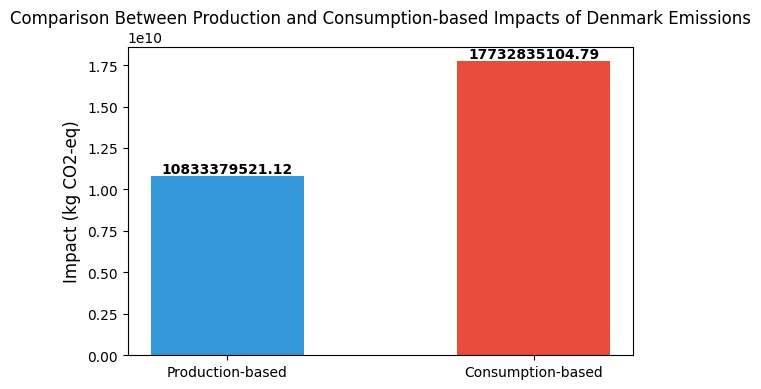

In [17]:
# create a bar graph 
labels = ['Production-based', 'Consumption-based']
values = [prod_DK_plastics_total, con_DK_plastics_total]
plt.subplots(figsize=(6,4))
bars = plt.bar(labels, values, color=['#3498db','#e74c3c'], width=0.5)
plt.ylabel('Impact (kg CO2-eq)', fontsize=12)
plt.title("Comparison Between Production and Consumption-based Impacts of Denmark Emissions")
# 在柱子上方标注具体数值
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.2f}',
             ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


In [18]:
# task6: 文字部分，批判性思考；关于项目的 discussion 和 limitations 部分
# task7：通过 excel 手动计算以上内容，彻底理解全球供应链的“洋葱结构“

### Modul4-Task1

In [19]:
# Task1: 计算在特定地区，如果在这个行业多花 100 万欧元，会给全球供应链带来多少环境影响（这个结果被称为：impact intensity）

# Pick scenario
region = 'DK'
industry = 'Plastics, basic'
extension = 'GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)'

# Denmark’s final demand (summed across households, gov, etc.)
Y_region = Y.T.groupby(level="region").sum().T[region]

# Find index position of the chosen industry
idx = Y_region.index.get_loc((region, industry))

# Create a final demand vector where ONLY this industry = 1 MEUR
y_vector = np.zeros(len(Y_region))
y_vector[idx] = 1                                # 1 million EUR
y_vector = pd.Series(y_vector, index=Y.index)    # Convert to pandas Series

# Select only the GHG row (your chosen extension name)
S_ghg = exio3.impacts.S.loc[extension]

# Diagonalize S_ghg → needed to keep industry-level contributions separate
S_ghg_hat = pd.DataFrame(
    np.diag(S_ghg),
    index=A.index,
    columns=A.columns
)

D_ghg = S_ghg_hat.dot(L).dot(y_vector)   # kg CO2e per MEUR
total_impact_MEUR = D_ghg.sum()          # kg CO2e per MEUR (single number)

print(f"Carbon footprint of 1 EUR of {industry} in {region}: {total_impact_MEUR/10**6:.7f} kg CO2e/EUR")

Carbon footprint of 1 EUR of Plastics, basic in DK: 0.2864054 kg CO2e/EUR


### Module4-Task2：Extract Top5 contributing industries

In [20]:
def find_top_5(series):
    if isinstance(series, pd.DataFrame):
        series = series.sum(axis=1)
    sorted_series = series.sort_values(ascending=False)
    top5 = sorted_series.head(5)
    return list(top5.index), list(top5.values)

print("TOP 5 CONTRIBUTORS:")
industries, values = find_top_5(D_ghg)

for name, val in zip(industries, values):
    print(f"{name}: {val/1e6:.3f} kt CO2e pr MEURO") # or other appropriate unit



TOP 5 CONTRIBUTORS:
('DK', 'Sea and coastal water transportation services'): 0.056 kt CO2e pr MEURO
('DK', 'Plastics, basic'): 0.052 kt CO2e pr MEURO
('DK', 'Steam and hot water supply services'): 0.019 kt CO2e pr MEURO
('WA', 'Sea and coastal water transportation services'): 0.009 kt CO2e pr MEURO
('WM', 'Sea and coastal water transportation services'): 0.007 kt CO2e pr MEURO


In [21]:
industries, values = find_top_5(D_ghg)

# Make labels safe strings and values plain floats 
industries = [
    " - ".join(lbl) if isinstance(lbl, tuple) else str(lbl)
    for lbl in industries
]
values = np.asarray(values, dtype=float).ravel()

# Unit conversion: kg -> kilotonnes for nicer axes 
values_kt = values / 1e6 # I.e., 1 000 000 kg = 1 kt

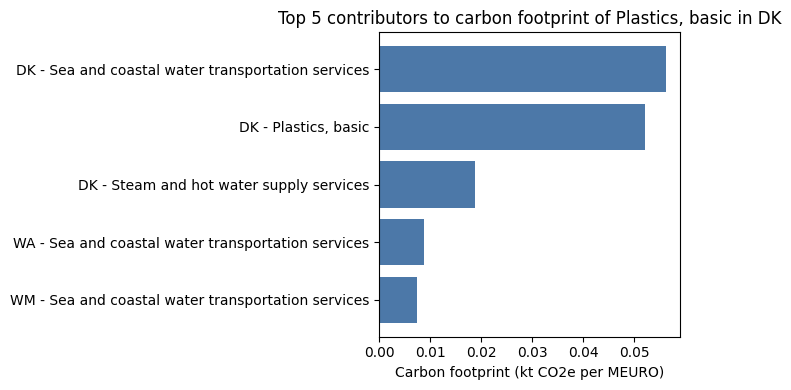

In [22]:
# Plot 
plt.figure(figsize=(7, 4))
plt.barh(industries, values_kt, color="#4C78A8")
plt.gca().invert_yaxis()  # largest bar at the top

plt.xlabel("Carbon footprint (kt CO2e per MEURO)") # or other appropriate unit
plt.title(f"Top 5 contributors to carbon footprint of {industry} in {region}")
plt.tight_layout()
plt.show()

### Module4-Task3: SPA结构路径分析
##### 代码通过数学上的幂级数展开，将复杂度全球供应链拆解为不同的层级（Ties/Steps）

In [23]:
# Task3A：计算各层级的排放贡献，算出的是供应链中每一级 Tier 的总环境负担
# calculating each A^k as a DataFrame
def matrix_power_df(A_df: pd.DataFrame, k: int) -> pd.DataFrame:
    A_k = np.linalg.matrix_power(A_df.values, k) # Compute A^k as a numpy array
    return pd.DataFrame(A_k, index=A_df.index, columns=A_df.columns) # Convert back to DataFrame with same index/columns


# compute SPA totals for orders 0..K-1
def spa_totals_by_order(S_row: pd.Series, A_df: pd.DataFrame, y: pd.Series, K: int = 4): 
    totals = [] # Initialize list to store totals for each order k
    for k in range(K): # Loop over orders 0..K-1 
        A_k = matrix_power_df(A_df, k) # Compute A^k as a DataFrame
        D_k = float(S_row.dot(A_k).dot(y))  # Compute D^(k) = S * A^k * y as a scalar (e.g. for GHG kg CO2e per MEUR) 
        totals.append(D_k) # Store the total for this order k
    return totals

# Compute steps 0..3 (i.e., I, A, A^2, A^3)
K = 4 # Number of steps to compute (0..K-1)
step_labels = [f"Step {k+1}" for k in range(K)]  # Labels for the x-axis (Step 1, Step 2, Step 3, Step 4), i.e., Step 1=I*y, Step 2=A*y, ...
totals_kg = spa_totals_by_order(S_ghg, A, y_vector, K=K)  # Compute totals for orders 0..K-1 (uses S_ghg, A, y_vector from Task 1))



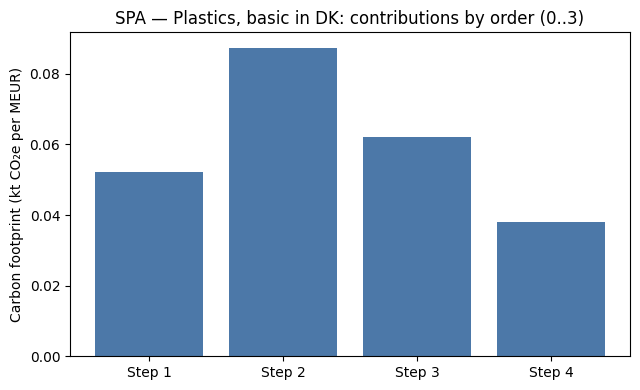

SPA — Plastics, basic in DK
  Step 1: 0.052 kt CO₂e per MEUR
  Step 2: 0.087 kt CO₂e per MEUR
  Step 3: 0.062 kt CO₂e per MEUR
  Step 4: 0.038 kt CO₂e per MEUR


In [25]:
### Plot the results
totals_kt = [x / 1e6 for x in totals_kg]  # 1 kt = 1,000,000 kg
plt.figure(figsize=(6.5, 4))
plt.bar(step_labels, totals_kt, color="#4C78A8")
plt.ylabel("Carbon footprint (kt CO₂e per MEUR)") # Tune depending on your impact/extension (e.g. kg CO₂e per MEUR, or m³ water per MEUR, etc.)
plt.title(f"SPA — {industry} in {region}: contributions by order (0..3)")
plt.tight_layout()
plt.show()

# --- Print a short summary ---
print(f"SPA — {industry} in {region}")
for k, val_kg in enumerate(totals_kg, start=1):
    print(f"  Step {k}: {val_kg/1e6:,.3f} kt CO₂e per MEUR") #Adjust according to your unit


###### Step 1 (k=0): 代表 直接排放 (Direct Impact) 。对于你的 PLA 项目，这是指丹麦工厂内部消耗能源和转化乳酸时产生的直接排放。
###### Step 2 (k=1): 代表 一级供应商 (1st Tier Suppliers)。反映了工厂购买的电力、化学原料或直接运输服务的排放。
###### Step 3 & 4 (k=2,3): 代表 深层供应商 (Upstream Suppliers)。这是 SPA 的核心价值，它揭示了由于购买一级原材料而引发的更远端的经济活动（如化肥生产或远洋采矿）。
###### 项目意义： 通过对比 Step 1 到 Step 4 的数值，你可以评估 PLA 供应链的“重心”在哪里 。如果 Step 3 的数值依然很高，说明该产品的环境影响具有高度的上游依赖性，仅靠工厂内部减排是不够的。

In [26]:
# Task3B:对角化矩阵，看谁在每一层贡献了排放
def spa_series_by_order(S_hat: pd.DataFrame, A_df: pd.DataFrame, y: pd.Series, K: int = 4):
    series_per_step = []
    for k in range(K):
        A_k = matrix_power_df(A_df, k)
        D_k = S_hat.dot(A_k).dot(y)  # pd.Series aligned to industries
        series_per_step.append(D_k)
    return series_per_step

def stringify_multiindex(index_like):
    def _one(lbl):
        if isinstance(lbl, tuple):
            return " - ".join(map(str, lbl))
        return str(lbl)
    return [_one(x) for x in index_like]

# Compute the by-origin series for steps 0...3
series_steps = spa_series_by_order(S_ghg_hat, A, y_vector, K=4)  # uses S_ghg_hat, A, y_vector


In [27]:
### Build Top-5 tables for each step
top_tables = []       # will hold one small df per step
wide_collect = {}     # for a combined wide table later

for k, ser in enumerate(series_steps, start=1):
    # Take absolute values just in case (should be non-negative for GHG, but safe):
    ser = ser.astype(float)

    # Get Top-5 using your helper
    labels, vals = find_top_5(ser)  # ← your helper function from Task 2, rename if you called it something else

    # Pretty labels and unit conversion
    labels_str = stringify_multiindex(labels)
    vals_kt = np.asarray(vals, dtype=float) / 1e6  # kg → kt

    # Neat table per step
    tbl = (
        pd.DataFrame(
            {"Contributor": labels_str, f"Step {k} (kt CO₂e per MEUR)": vals_kt} # adjust according to your units
        ).set_index("Contributor")
    )
    top_tables.append(tbl)

    # For a wide union across steps
    for lbl, v_kt in zip(labels_str, vals_kt):
        wide_collect.setdefault(lbl, {})[f"Step {k}"] = v_kt

### Concatenate the per-step Top-5 tables (stacked view)
stacked_top5 = pd.concat(top_tables, axis=0)


### Combined wide table: union of Top‑5 contributors across all steps
Table_all = (
    pd.DataFrame(wide_collect).T
    .reindex(columns=[f"Step {k}" for k in range(1, 5)])
    .sort_values(by=["Step 1","Step 2","Step 3","Step 4"], ascending=False) # align if you include more/fewer steps
    .fillna(0.0)
)
Table_all.columns = ['Step 1', 'Step 2', 'Step 3', 'Step 4']  # align naming

# --- Display / inspect ---
print("\nTOP-5 contributors per step (stacked):")
display(stacked_top5)

print("\nUnion of Top-5 across steps (wide):")
display(Table_all)


TOP-5 contributors per step (stacked):


,Step 1 (kt CO₂e per MEUR),Step 2 (kt CO₂e per MEUR),Step 3 (kt CO₂e per MEUR),Step 4 (kt CO₂e per MEUR)
Contributor,,,,
"DK - Plastics, basic",0.052047,NaN,NaN,NaN
AT - Paddy rice,0.000000,NaN,NaN,NaN
KR - Electricity by solar thermal,0.000000,NaN,NaN,NaN
KR - Electricity by nuclear,0.000000,NaN,NaN,NaN
KR - Electricity by hydro,0.000000,NaN,NaN,NaN
DK - Sea and coastal water transportation services,NaN,0.029109,NaN,NaN
DK - Steam and hot water supply services,NaN,0.016332,NaN,NaN
"US - Crude petroleum and services related to crude oil extraction, excluding surveying",NaN,0.003033,NaN,NaN
"NO - Crude petroleum and services related to crude oil extraction, excluding surveying",NaN,0.002657,NaN,NaN



Union of Top-5 across steps (wide):


,Step 1,Step 2,Step 3,Step 4
"DK - Plastics, basic",0.052047,0.000000,0.000000,0.000000
AT - Paddy rice,0.000000,0.000000,0.000000,0.000000
KR - Electricity by solar thermal,0.000000,0.000000,0.000000,0.000000
KR - Electricity by nuclear,0.000000,0.000000,0.000000,0.000000
KR - Electricity by hydro,0.000000,0.000000,0.000000,0.000000
DK - Sea and coastal water transportation services,0.000000,0.029109,0.015287,0.007164
DK - Steam and hot water supply services,0.000000,0.016332,0.001764,0.000000
"US - Crude petroleum and services related to crude oil extraction, excluding surveying",0.000000,0.003033,0.000000,0.000000
"NO - Crude petroleum and services related to crude oil extraction, excluding surveying",0.000000,0.002657,0.000000,0.000000
DK - Pigs,0.000000,0.002097,0.000000,0.000000


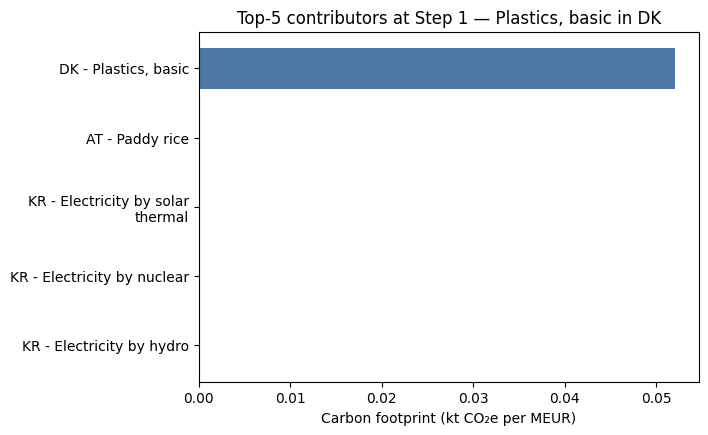

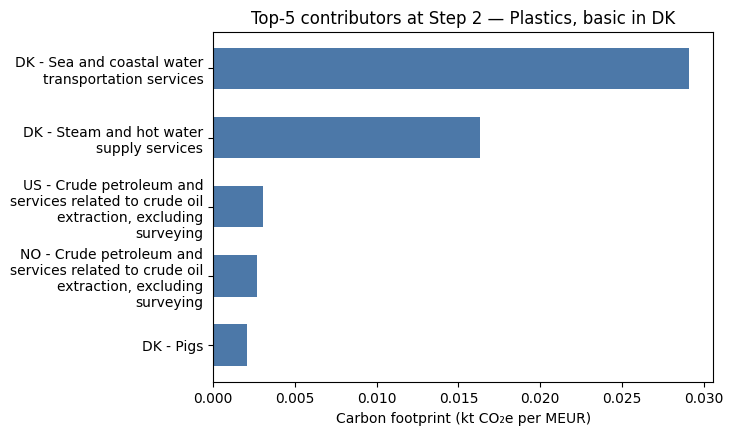

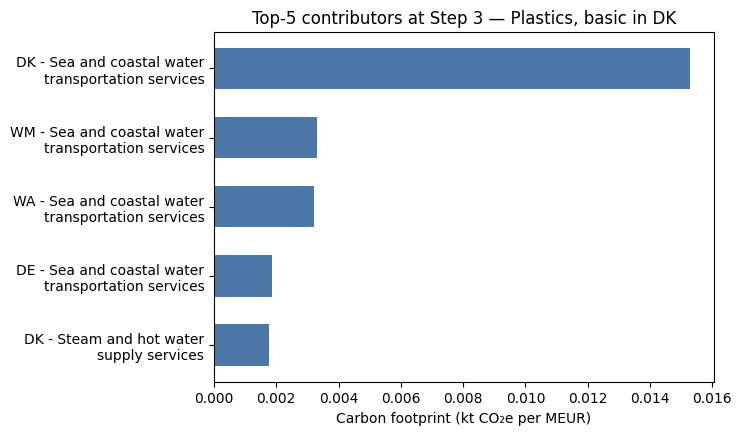

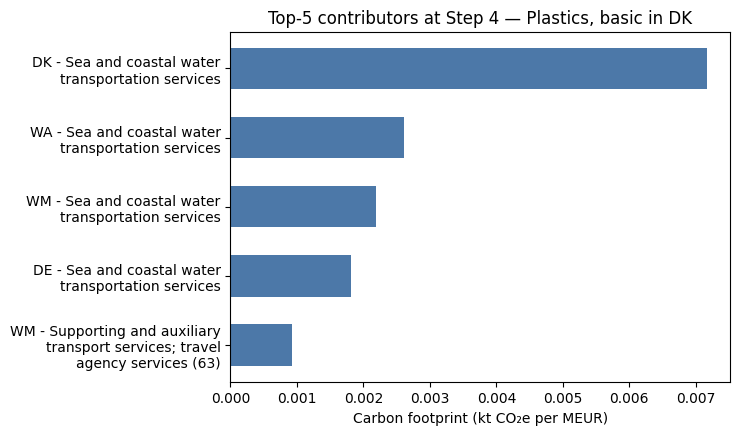

In [33]:
# Plots for each step's Top-5 contributors
import textwrap

for k, tbl in enumerate(top_tables, start=1):
    fig,ax = plt.subplots(figsize=(10, 5))
    vals = tbl.iloc[:, 0].values
    raw_lbls = tbl.index.tolist()
    lbls = [textwrap.fill(str(l), width=30) for l in raw_lbls]
    bars = ax.barh(lbls, vals, color="#4C78A8", height=0.6) # or define another colour as you like
    ax.invert_yaxis()
    ax.set_xlabel("Carbon footprint (kt CO₂e per MEUR)",fontsize=10)
    ax.set_title(f"Top-5 contributors at Step {k} — {industry} in {region}")
    plt.subplots_adjust(left=0.4, right=0.9,top=0.85, bottom=0.15)
    plt.show()
